# 02 · 实验可信度诊断与 ATE

本节回答：公开样本是否存在明显数据异常、X 能否预测 T、X 是否有结果预测信息、T/C 的平均结果差异是多少？可观测诊断不能证明所有因果识别假设成立。

In [1]:
from pathlib import Path
import sys, json, os
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'criteo_uplift').is_dir())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from criteo_uplift.runtime import configure_runtime
configure_runtime()
import numpy as np
import pandas as pd
from IPython.display import display, Image, HTML
from criteo_uplift.results import result_directory
RUN = result_directory('conversion_1000000_seed42', ROOT)
print('读取结果目录:', RUN.relative_to(ROOT))
manifest = json.loads((RUN / 'manifest.json').read_text())
print('分析对象:', manifest['primary_outcome'], '| 随机样本:', f"{manifest['sample_n']:,}")
print('seed:', manifest['seed'], '| 主预算:', manifest['selection']['primary_budget'])


读取结果目录: reports/published/conversion_1000000_seed42
分析对象: conversion | 随机样本: 1,000,000
seed: 42 | 主预算: 0.2


## ATE：差均值与不确定性

$$\hat\tau=\bar Y_1-\bar Y_0,\quad SE=\sqrt{s_1^2/n_1+s_0^2/n_0}.$$

95% CI 用非合并方差；双侧零效应检验使用零假设下的合并比例。绝对差以概率表示，乘 100 是百分点 pp，乘 100,000 是每十万人增量。相对提升为绝对差除以对照率。

全量 ATE 是描述性分析，不能直接解释成真实线上广告收益。

,outcome,n,n_control,n_treatment,response_control,response_treatment,ate,standard_error,ci_low,ci_high,p_value,relative_uplift
0,conversion,13979592,2096937,11882655,0.001938,0.003089,0.001152,0.000034,0.001085,0.001219,7.308263e-179,0.594488
1,visit,13979592,2096937,11882655,0.038201,0.048543,0.010342,0.000146,0.010056,0.010629,0.000000e+00,0.270737


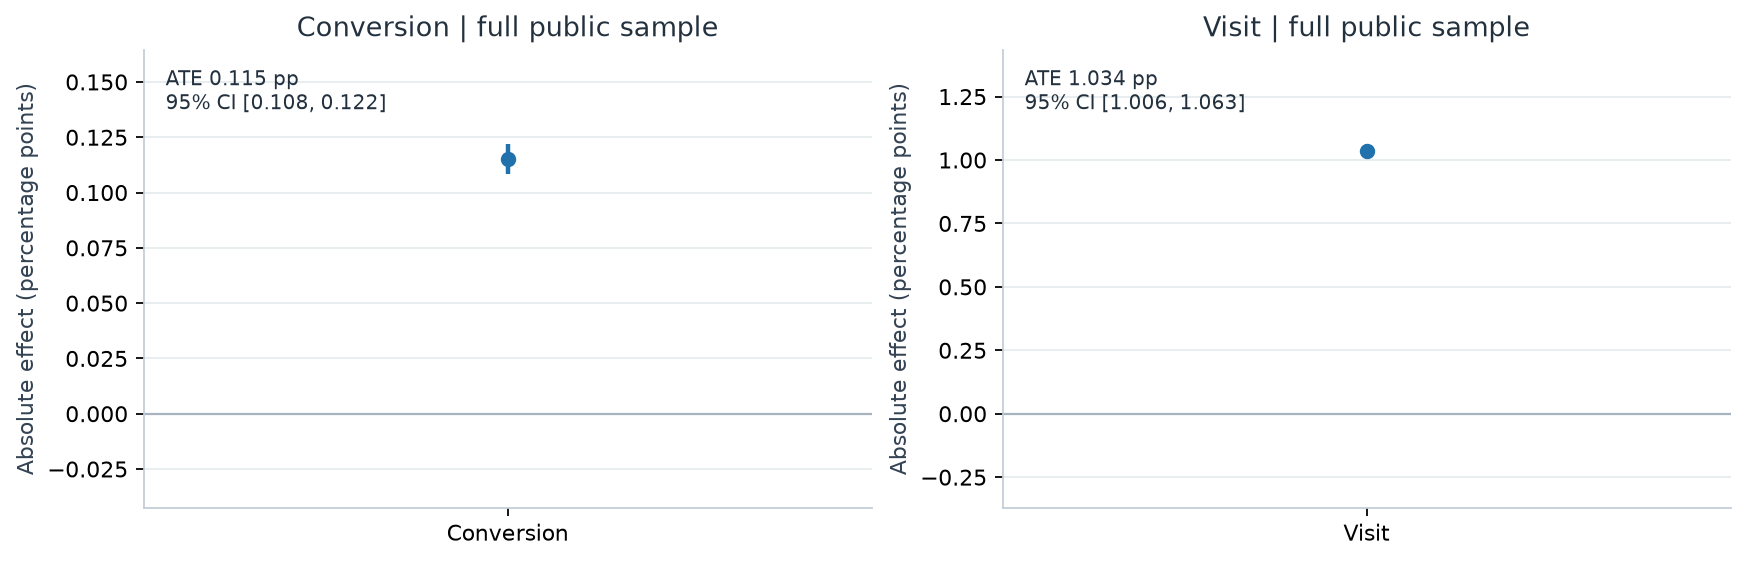

In [2]:
ate = pd.read_csv(RUN/'ate_full.csv')
display(ate)
display(Image(filename=str(RUN/'figures/ate_full.png')))

## SRM、协变量平衡与 C2ST

SRM 必须有外部给定的预设分流概率；不能拿观察到的 85% 当零假设再说通过。当前无设计参数，明确跳过。

SMD 衡量单变量均值差；KS 描述单变量分布差；C2ST 用 Logistic + 小型树模型检查联合分布的可区分性。仅取训练集中的 20,000 个随机样本，固定训练/留出划分，每次在各划分内置换 T 并完整重拟合。99 次置换，p 值最小粒度 0.01；两模型同时看，给出 Holm 校正。

不显著表示“未发现足够证据”，不能表述为证明随机化。

{'n_treatment': 11882655,
 'n_control': 2096937,
 'observed_ratio': 0.8500001287591226,
 'expected_ratio': None,
 'chi2': None,
 'pvalue': None,
 'status': 'skipped',
 'reason': 'Design allocation is unknown; the observed ratio cannot be its own SRM null.'}

,feature,n_treatment,n_control,mean_treatment,mean_control,smd,abs_smd,ks_statistic,ks_pvalue
0,f0,510246,89754,19.623768,19.684768,-0.011339,0.011339,0.008098,8.940086e-05
1,f1,510246,89754,10.070420,10.067637,0.027854,0.027854,0.002908,5.374569e-01
2,f2,510246,89754,8.446196,8.448253,-0.006865,0.006865,0.005024,4.227052e-02
3,f3,510246,89754,4.169323,4.234000,-0.049745,0.049745,0.015277,6.641457e-16
4,f4,510246,89754,10.339331,10.335186,0.012261,0.012261,0.002898,5.421680e-01
5,f5,510246,89754,4.027341,4.039375,-0.029047,0.029047,0.004923,4.932557e-02
6,f6,510246,89754,-4.182569,-4.012623,-0.037567,0.037567,0.012554,7.050524e-11
7,f7,510246,89754,5.101631,5.084254,0.014615,0.014615,0.004923,4.932557e-02
8,f8,510246,89754,3.933312,3.934539,-0.021822,0.021822,0.008626,2.318859e-05
9,f9,510246,89754,16.060561,15.871833,0.027286,0.027286,0.007725,2.201190e-04


,model,roc_auc,average_precision,log_loss,brier,dummy_log_loss,dummy_roc_auc,dummy_brier,train_treatment_ratio,test_treatment_ratio,pvalue,null_auc_mean,permutations,pvalue_holm
0,logistic,0.509788,0.853982,0.426485,0.129065,0.426735,0.5,0.129128,0.847571,0.847667,0.26,0.502261,99,0.52
1,hgb,0.498291,0.847776,0.428964,0.129658,0.426735,0.5,0.129128,0.847571,0.847667,0.57,0.500252,99,0.57


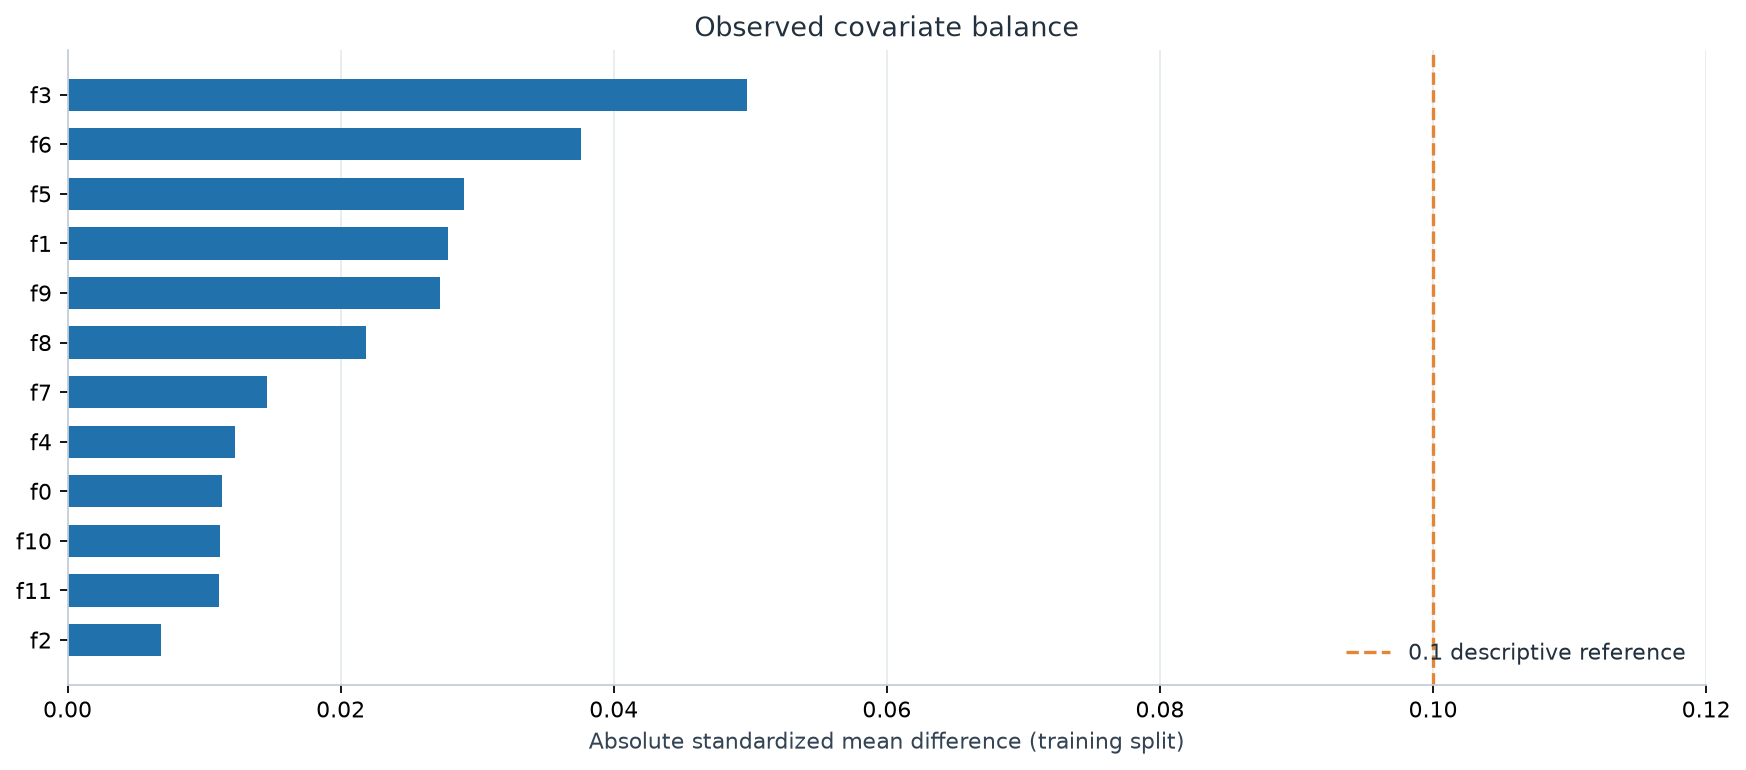

In [3]:
display(json.loads((RUN/'srm.json').read_text()))
display(pd.read_csv(RUN/'balance.csv'))
display(pd.read_csv(RUN/'c2st.csv'))
display(Image(filename=str(RUN/'figures/balance.png')))

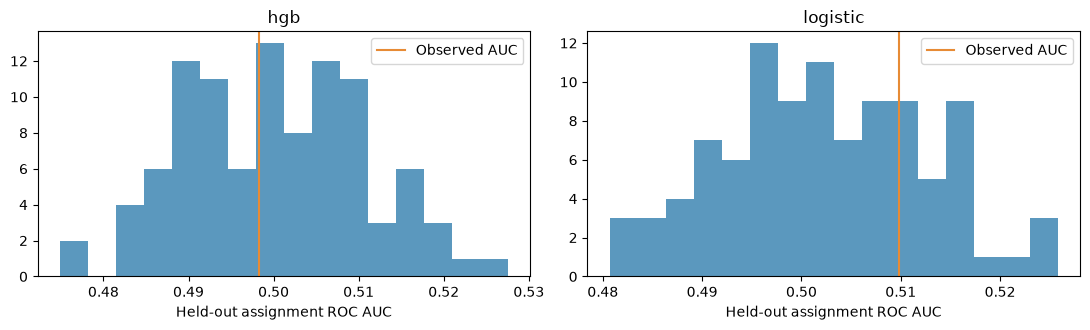

In [4]:
null = pd.read_csv(RUN/'c2st_null.csv')
observed = pd.read_csv(RUN/'c2st.csv').set_index('model')
import matplotlib.pyplot as plt
fig, axes=plt.subplots(1,2,figsize=(11,3.4))
for (name, group), ax in zip(null.groupby('model'), axes):
    ax.hist(group.roc_auc,bins=16,color='#2476a8',alpha=.75)
    ax.axvline(observed.loc[name,'roc_auc'],color='#e78b35',label='Observed AUC')
    ax.set_title(name);ax.set_xlabel('Held-out assignment ROC AUC');ax.legend()
plt.tight_layout();plt.show()

## 可学习性

Dummy 使用训练集平均结果率；Logistic / HistGradientBoosting 只在训练集拟合，在 validation 比较 LogLoss、average precision、Brier、ROC-AUC。分别查看整个样本和两个 treatment 臂，并分别检查 visit / conversion。

Outcome 可预测不等于 CATE 可预测；这些分类指标不能替代 AUUC、Qini 或策略增量。

In [5]:
learning = pd.read_csv(RUN/'learnability.csv')
display(learning)

,scope,outcome,n_train,n_validation,positive_rate_train,positive_rate_validation,model,status,roc_auc,average_precision,log_loss,brier
0,whole,visit,600000,200000,0.046762,0.046870,dummy,computed,0.500000,0.046870,0.189194,0.044673
1,whole,visit,600000,200000,0.046762,0.046870,logistic,computed,0.931984,0.478526,0.111607,0.031408
2,whole,visit,600000,200000,0.046762,0.046870,hgb,computed,0.944163,0.504059,0.105148,0.030132
3,treatment,visit,510246,170083,0.048379,0.048858,dummy,computed,0.500000,0.048858,0.195143,0.046472
4,treatment,visit,510246,170083,0.048379,0.048858,logistic,computed,0.932179,0.487910,0.114608,0.032359
5,treatment,visit,510246,170083,0.048379,0.048858,hgb,computed,0.943901,0.512811,0.108101,0.031072
6,control,visit,89754,29917,0.037569,0.035565,dummy,computed,0.500000,0.035565,0.153640,0.034304
7,control,visit,89754,29917,0.037569,0.035565,logistic,computed,0.928838,0.424461,0.092979,0.025548
8,control,visit,89754,29917,0.037569,0.035565,hgb,computed,0.944837,0.447234,0.087337,0.024435
9,whole,conversion,600000,200000,0.002882,0.002880,dummy,computed,0.500000,0.002880,0.019724,0.002872


## 可独立复用的函数

```python
from criteo_uplift.diagnostics import c2st, covariate_balance, learnability, srm_summary
from criteo_uplift.evaluation import ate_summary
# c2st(train, FEATURES, sample_size=20_000, permutations=99, seed=42)
# ate_summary(frame['conversion'], frame['treatment'])
```

全量聚合量来源于流式扫描，不需要把 3 GB CSV 整体读进内存。